Part 3. Estimating a Mixture of Normals (30 points)

Now assume the terminal stock price follows a mixture of two normal distributions:

$$
f(S_T)=w\phi(S_T;\mu_1,\sigma_1)
+(1-w)\phi(S_T;\mu_2,\sigma_2).
$$

--- 

First, we need to upload the data for calls saved in part 1 

In [1]:
import pandas as pd
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
from pathlib import Path


PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'part1_outputs'

processed_calls = pd.read_csv(PROCESSED_DIR / 'VZ_part1_clean_calls.csv')

processed_calls



,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
0,2025-03-10,2025-03-14,25.0,21.45,21.70,21.575,0.25,0.011587,3567,46.545,0.010959,0.044504
1,2025-03-10,2025-03-14,30.0,16.50,16.70,16.600,0.20,0.012048,3569,46.545,0.010959,0.044504
2,2025-03-10,2025-03-14,31.0,15.45,15.75,15.600,0.30,0.019231,3571,46.545,0.010959,0.044504
3,2025-03-10,2025-03-14,32.0,14.45,14.75,14.600,0.30,0.020548,3573,46.545,0.010959,0.044504
4,2025-03-10,2025-03-14,33.0,13.50,13.70,13.600,0.20,0.014706,3575,46.545,0.010959,0.044504
5,2025-03-10,2025-03-14,35.0,11.40,11.70,11.550,0.30,0.025974,3579,46.545,0.010959,0.044504
6,2025-03-10,2025-03-14,36.0,10.50,10.70,10.600,0.20,0.018868,3581,46.545,0.010959,0.044504
7,2025-03-10,2025-03-14,36.5,9.90,10.20,10.050,0.30,0.029851,3583,46.545,0.010959,0.044504
8,2025-03-10,2025-03-14,37.0,9.45,9.75,9.600,0.30,0.031250,3585,46.545,0.010959,0.044504
9,2025-03-10,2025-03-14,37.5,8.95,9.25,9.100,0.30,0.032967,3587,46.545,0.010959,0.044504


Now we define by defining the required parameters: 

- $S_t$
- $\mu_1$
- $\sigma_1$
- $\mu_2$
- $\sigma_2$
- $w$

In [2]:
K = processed_calls['strike'].to_numpy()
C_obs = processed_calls['mid'].to_numpy()

S_0 = processed_calls['S0'].iloc[0]
T = processed_calls['T'].iloc[0]
r = processed_calls['r'].iloc[0]

We will part from the Bachelier Formula

$$
C_i = \Beta(\mu_i - K) \Phi(d) + \Beta \sigma \sqrt{T} \phi(d)  \\
\text{where } \\
d = \frac{\mu_i - K}{\sigma\sqrt{T}} \\
and \\
\Beta = e^{-rT}
$$

Lets first plot the distribution of call prices realtive to the strike price

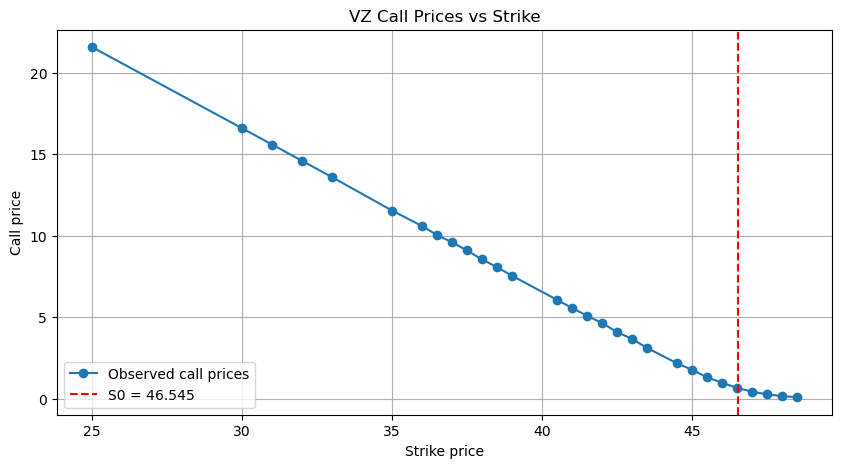

In [3]:
import numpy as np
import matplotlib.pyplot as plt


order = np.argsort(K)
K = K[order]
C_obs = C_obs[order]

plt.figure(figsize=(10, 5))
plt.plot(K, C_obs, "o-", label="Observed call prices")
plt.axvline(S_0, color="red", linestyle="--", label=f"S0 = {S_0:.3f}")
plt.xlabel("Strike price")
plt.ylabel("Call price")
plt.title("VZ Call Prices vs Strike")
plt.legend()
plt.grid(True)
plt.show()

The a raw density approximated by the gradient of the call relative to the strike price and the second derivative.

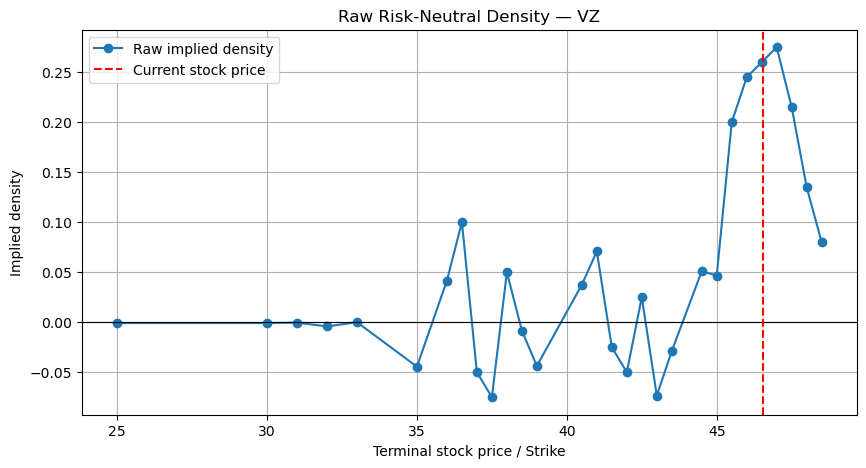

In [4]:
# First derivative with respect to strike
dC_dK = np.gradient(C_obs, K)

# Second derivative
d2C_dK2 = np.gradient(dC_dK, K)

# Breeden-Litzenberger density estimate
density = np.exp(r * T) * d2C_dK2

plt.figure(figsize=(10, 5))
plt.plot(K, density, "o-", label="Raw implied density")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(S_0, color="red", linestyle="--", label="Current stock price")
plt.xlabel("Terminal stock price / Strike")
plt.ylabel("Implied density")
plt.title("Raw Risk-Neutral Density — VZ")
plt.legend()
plt.grid(True)
plt.show()

Let us do the model first by computing a function for the bachelier call: ``bach_call`` and the mixture call ``mix_call``. 
for the mix_call fucntion we are using the parameter $\theta$ such thta $\theta = (\mu_1, \sigma_1, \mu_2, \sigma_2, w)$

In [5]:
from scipy.stats import norm
def bach_call(r, mu, K, sigma, T):

    B = np.exp(-r*T)
    d = (mu-K)/(sigma*np.sqrt(T))

    c_price = B*(mu-K)*norm.cdf(d) + B*sigma*np.sqrt(T)*norm.pdf(d)

    return c_price

def mix_call(K, theta, r, T):
    mu1, sigma1, mu2, sigma2, w = theta

    call_mix = w* bach_call(r, mu1, K, sigma1, T) + (1-w)*bach_call(r, mu2, K, sigma2, T)
    return call_mix



Now we define a fucntion to optimize `optim_fun` where we can compare the call prices given by our mixture model vs the observed prices. The optimization will be to minimize the mean square errors

In [6]:
def optim_fun(theta, K, C_obs, r, T):
    C_model = mix_call(K, theta, r, T)
    return np.sum((C_model - C_obs)**2)


We will use the ``minimize`` function from the ``scipy`` package for minimizing the function and will make a initial parameter *theta_ini* with random rumbers:

- $\mu_1 \sim Unif(S_0 - 2, S_0)$
- $\sigma_1 \sim Unif(0.3, 2)$
- $\mu_2 \sim Unif(S_0, S_0+2)$
- $\sigma_2 \sim Unif(0.3, 2)$
- $w \sim Unif(0.2,0.8)$

With the following bounds:
- $\sigma_1 > 0$
- $\sigma_2 > 0$
- $0 \leq w \leq 1$



In [7]:
from scipy.optimize import minimize
rand_seed = 123

np.random.seed(rand_seed)
theta_ini = (
    np.random.uniform(S_0 - 2, S_0),
    np.random.uniform(0.3, 2),
    np.random.uniform(S_0, S_0 + 2),
    np.random.uniform(0.3, 2),
    np.random.uniform(0.2, 0.8)
)

bounds = [
    (None, None),  # mu1
    (1e-6, None),  # sigma1 > 0
    (None, None),  # mu2
    (1e-6, None),  # sigma2 > 0
    (0, 1)         # 0 <= w <= 1
]
res = minimize(optim_fun, theta_ini, args= (K, C_obs, r, T), method="L-BFGS-B", bounds=bounds)


In [8]:
print("Success:", res.success)
print("Message:", res.message)
print("Parameters:", res.x)
print("Objective:", res.fun)

Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Parameters: [4.03885687e+01 4.57349038e+00 4.66939850e+01 1.41880623e+01
 1.71057217e-02]
Objective: 0.013955715297419397


This result gives us a mixture where there is a higher weight for $mu_2$, however we will test for 100 initial guesses in case the opitmizer converged to a local minimum instead of the global one

In [9]:
results = []

rng = np.random.default_rng(123)

for i in range(100):
    theta0 = (
        rng.uniform(S_0 - 2, S_0),
        rng.uniform(0.3, 20),
        rng.uniform(S_0, S_0 + 2),
        rng.uniform(0.3, 20),
        rng.uniform(0.1, 0.9)
    )

    result = minimize(
        optim_fun,
        theta0,
        args=(K, C_obs, r, T),
        method="L-BFGS-B",
        bounds=bounds
    )

    if result.success:
        results.append(result)

best = min(results, key=lambda result: result.fun)

print("Best parameters:", best.x)
print("Best objective:", best.fun)
print("Successful optimizations:", len(results))

Best parameters: [4.04999999e+01 1.00000000e-06 4.66966032e+01 1.41632682e+01
 1.77609412e-02]
Best objective: 0.013872288877212997
Successful optimizations: 100


In [20]:
mu1, sigma1, mu2, sigma2, w = best.x

C_model = mix_call(K, best.x, r, T)

rmse = np.sqrt(np.mean((C_model - C_obs)**2))

print("RMSE:", rmse)
print("Mixture mean:", w*mu1 + (1-w)*mu2)

RMSE: 0.021871323436623895
Mixture mean: 46.58654573387688


Let's now plot our mixed normal density

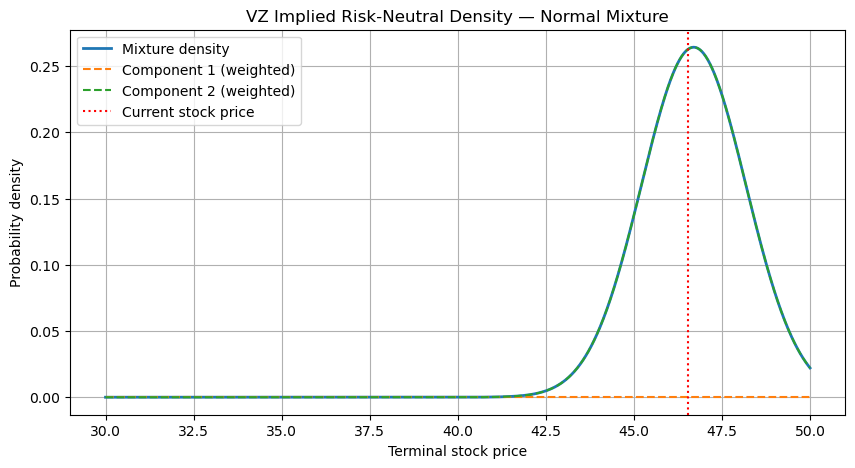

In [21]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

sigma_T1 = sigma1*np.sqrt(T)
sigma_T2 = sigma2*np.sqrt(T)

s = np.linspace(30, 50, 1000)

density1 = w * norm.pdf(s, mu1, sigma_T1)
density2 = (1-w) * norm.pdf(s, mu2, sigma_T2)

density_mix = density1 + density2

plt.figure(figsize=(10, 5))

plt.plot(s, density_mix, label="Mixture density", linewidth=2)
plt.plot(s, density1, "--", label="Component 1 (weighted)")
plt.plot(s, density2, "--", label="Component 2 (weighted)")

plt.axvline(S_0, color="red", linestyle=":", label="Current stock price")

plt.xlabel("Terminal stock price")
plt.ylabel("Probability density")
plt.title("VZ Implied Risk-Neutral Density — Normal Mixture")
plt.legend()
plt.grid(True)
plt.show()

New we compare the two models, the lognormal one and the normal mixture and compare there results in the following table:

In [22]:
# table report


# Mean
mean_mix = w * mu1 + (1 - w) * mu2

# Variance and standard deviation
var_mix = (
    w * (s1**2 + (mu1 - mean_mix)**2)
    + (1-w) * (s2**2 + (mu2 - mean_mix)**2)
)

std_mix = np.sqrt(var_mix)

# Third central moment
m3 = (
    w * ((mu1 - mean_mix)**3
         + 3 * (mu1 - mean_mix) * sigma_T1**2)
    + (1-w) * ((mu2 - mean_mix)**3
               + 3 * (mu2 - mean_mix) * sigma_T2**2)
)

skew_mix = m3 / std_mix**3

# Probability of a 5% decline
threshold = 0.95 * S_0

prob_decline_mix = (
    w * norm.cdf(threshold, loc=mu1, scale=sigma_T1)
    + (1-w) * norm.cdf(threshold, loc=mu2, scale=sigma_T2)
)

# RMSE
rmse_mix = np.sqrt(np.mean((C_model - C_obs)**2))

columns = ['Measure', 'Lognormal', 'Normal Mixture']
measure = ['Mean terminal stock price', 'Skeweness', 'Probability of a 5% price decline', 'Root mean squared pricing error ']

data_mix = [mean_mix, skew_mix, prob_decline_mix, rmse_mix]
table_report = pd.DataFrame(columns = columns, index = list(range(len(measure))))
table_report['Measure'] = measure
table_report['Normal Mixture'] = data_mix

table_report

,Measure,Lognormal,Normal Mixture
0,Mean terminal stock price,NaN,46.586546
1,Skeweness,NaN,-0.687235
2,Probability of a 5% price decline,NaN,0.064196
3,Root mean squared pricing error,NaN,0.021871


Changes and analysis depends on waht Moctran will tell me 

In [18]:
w


np.float64(0.01776094118019932)